# 06 · Modelos — Reto AgroCebada 2026

## Qué hace este cuaderno
Entrena una escalera de modelos, de lo más simple a lo más elaborado, y evalúa **cada uno exactamente en los mismos pliegues de validación** fijados en el cuaderno 05, contra la referencia oficial (media municipal, RMSE ≈ 0.498 t/ha). Un modelo solo se considera una mejora si supera a la referencia por más que el ruido entre pliegues. Todo lo que usa el rendimiento (selección de variables, ajuste de hiperparámetros) ocurre **dentro** de cada pliegue de entrenamiento.

## Qué mostraron los datos antes de diseñar este cuaderno
Tres observaciones exploratorias guiaron el diseño:
1. **Las variables satelitales solas no superan a la ubicación.** Un modelo ridge con las mejores variables de Planet perdió frente a la media municipal (+0.006 t/ha), y los bosques aleatorios y el *boosting* perdieron con claridad (+0.06 a +0.10): con 138 parcelas memorizan ruido.
2. **El error está concentrado.** En Chignahuapan la mitad de las parcelas está entre 4.38 y 4.69 t/ha, pero unas pocas parcelas de 2.2–3.0 t/ha dominan el RMSE. En Calpulalpan los rendimientos solo toman los valores 2.5, 3.0 o 3.5 t/ha, así que parte del error es redondeo que ningún modelo puede predecir.
3. **Las parcelas vecinas comparten su sorpresa.** Lo que la media municipal no explica de una parcela se correlaciona (+0.28) con lo que no explica de la parcela más cercana del mismo municipio (a unos 0.4 km), y el efecto desaparece en ~1 km. Es variación a escala de finca (mismo productor, mismo manejo, mismo suelo). Las 59 parcelas de predicción están justo a esa distancia de las de entrenamiento (mediana 0.35 km).

El punto 3 pide un **modelo espacial de corto alcance**, que es lo que hace nuestro modelo propio.

## La escalera de modelos
| # | Modelo | Idea |
|---|---|---|
| 0 | Media municipal | referencia oficial |
| 1 | Ridge sobre residuos | efecto lineal de las mejores variables sobre lo que la media municipal no explica (número de variables elegido por validación cruzada interna) |
| 2 | Bosque aleatorio sobre residuos | no lineal, 20 variables |
| 3 | LightGBM sobre residuos | árboles poco profundos con *boosting*, muy regularizados, 20 variables |
| 4 | PG espacial sobre residuos | media municipal + kriging de los residuos con núcleo Matérn (scikit-learn) |
| 5 | **PG jerárquico** (propio) | efecto aleatorio de municipio + efecto espacial a escala de finca + ruido, todo aprendido de los datos |
| 6 | **PG jerárquico + variables** (propio) | añade un efecto lineal de las mejores variables; *el propio modelo elige* si usa 0, 3, 6 o 10 variables según la evidencia bayesiana |
| 7 | Kriging de regresión | ridge sobre variables y luego un PG espacial sobre lo que ridge no explica |

## Cómo se juzgan las diferencias
En cada uno de los 50 pliegues calculamos RMSE(modelo) − RMSE(referencia). La diferencia media y su error estándar (EE) indican si un modelo realmente ayuda. Reportamos dos EE:
- el **EE simple** (dispersión de las 50 diferencias ÷ √50);
- el **EE corregido** de Nadeau y Bengio (2003), que toma en cuenta que los pliegues repetidos reutilizan las mismas parcelas; es mayor y más honesto.

**Regla de decisión** (fijada antes de modelar): un modelo se considera una mejora si supera a la referencia por más de 1 EE simple. También reportamos si pasa la prueba corregida, más estricta.

## Salidas
| Archivo | Contenido |
|---|---|
| `src/agc_models.py` | código compartido: selección de variables dentro del pliegue, preprocesamiento y el PG jerárquico |
| `models/oof_nb06.parquet` | predicciones fuera de pliegue de cada modelo y cada repetición (para el ensamble y los intervalos del cuaderno 07) |
| `models/leaderboard_nb06.csv` | métricas, diferencias contra la referencia y decisiones |
| `qa/figures/nb06_*`, `qa/nb06_report.md` | figuras y reporte |

**Tiempo de ejecución:** ~10–15 minutos con 10 repeticiones (con `N_REPEATS = 3` corre en ~4 minutos).

## 0 · Preparación

In [1]:
# 0.1 · Librerías, Drive y rutas
import os, sys, json, time, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
try:
    import lightgbm as lgb
    HAVE_LGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    HAVE_LGB = False

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content/drive/MyDrive/AgroCebada") if IN_COLAB else Path(os.environ.get("AGC_BASE", "AgroCebada"))
FEATURES, MODELS, QA, SRC = BASE / "features", BASE / "models", BASE / "qa", BASE / "src"
FIG = QA / "figures"
for d in [MODELS, FIG, SRC]:
    d.mkdir(parents=True, exist_ok=True)
for f in [FEATURES / "master.parquet", FEATURES / "feature_catalog_all.csv", MODELS / "cv_folds.json", MODELS / "cv_spatial.json"]:
    assert f.exists(), f"Falta {f}: ejecuta primero el cuaderno 05."
SEED = 42
if "display" not in globals():
    display = print
print(f"BASE = {BASE} | Colab: {IN_COLAB} | LightGBM: {HAVE_LGB}")

Mounted at /content/drive
BASE = /content/drive/MyDrive/AgroCebada | Colab: True | LightGBM: True


In [2]:
# 0.2 · Configuración (fijada antes de correr cualquier modelo)
N_REPEATS = 10                     # 10 = evaluación completa (50 pliegues); 3 = corrida rápida (15 pliegues)
K_GRID_RIDGE = [5, 10, 20, 40]     # ridge: número de variables elegido por VC interna de 5 pliegues
K_TREES = 20                       # bosque aleatorio / LightGBM: número de variables
HGP_K_GRID = [0, 3, 6, 10]         # PG jerárquico: números de variables comparados por evidencia bayesiana
HGP_RESTARTS = 2
Z80, Z90 = 1.2816, 1.6449

COLORS = {"baseline": "#9a9a94", "features": "#86b6ef", "spatial": "#2a78d6", "custom": "#1c5cab"}
GREY, RED, INK = "#9a9a94", "#e34948", "#2b2b28"
# nombres en español para las figuras (los identificadores internos no cambian)
NOMBRES = {"0 municipality mean": "0 media municipal", "1 ridge on residuals": "1 ridge sobre residuos",
           "2 random forest on residuals": "2 bosque aleatorio sobre residuos", "3 LightGBM on residuals": "3 LightGBM sobre residuos",
           "4 spatial GP on residuals": "4 PG espacial sobre residuos", "5 hierarchical GP": "5 PG jerárquico",
           "6 hierarchical GP + features": "6 PG jerárquico + variables", "7 regression kriging": "7 kriging de regresión"}
TIPOS = {"baseline": "referencia", "features": "variables", "spatial": "espacial", "custom": "propio"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": "#6b6b66",
                     "ytick.color": "#6b6b66", "font.size": 9, "legend.frameon": False})
CHECKS = []
def check(name, ok, detail="", warn_only=True, info=False):
    status = "INFO" if info else ("PASS" if ok else ("WARN" if warn_only else "FAIL"))
    rec = {"check": name, "status": status, "detail": str(detail)}
    for j, r in enumerate(CHECKS):
        if r["check"] == name:
            CHECKS[j] = rec
            break
    else:
        CHECKS.append(rec)
    print(f"[{status}] {name}" + (f" — {detail}" if detail != "" else ""))

In [3]:
# 0.3 · Tabla maestra, catálogo y pliegues
MASTER = pd.read_parquet(FEATURES / "master.parquet").set_index("ID_POLIGONO")
cat = pd.read_csv(FEATURES / "feature_catalog_all.csv", index_col=0)
cat.index.name = "feature"
MASTER["x_km"], MASTER["y_km"] = MASTER.x_m / 1000, MASTER.y_m / 1000
CANDS = [c for c in cat.index[cat.use_in_model.astype(bool)] if c in MASTER and MASTER[c].nunique() > 2]
CLUSTERS = cat.redundancy_cluster.dropna().astype(int).to_dict()
TR = MASTER[MASTER.is_train.astype(bool)].copy()
FOLDS = [f for f in json.loads((MODELS / "cv_folds.json").read_text())["folds"] if f["repeat"] < N_REPEATS]
SPATIAL = json.loads((MODELS / "cv_spatial.json").read_text())["folds"]
OFFICIAL = json.loads((MODELS / "baselines_cv.json").read_text()) if (MODELS / "baselines_cv.json").exists() else {}
print(f"{len(TR)} parcelas de entrenamiento · {len(CANDS)} variables candidatas · {len(FOLDS)} pliegues principales · {len(SPATIAL)} pliegues espaciales")

138 parcelas de entrenamiento · 264 variables candidatas · 50 pliegues principales · 5 pliegues espaciales


## 1 · ¿Por qué un modelo espacial? El semivariograma de lo que la ubicación no explica

Para cada par de parcelas de entrenamiento **del mismo municipio** tomamos sus residuos respecto a la media municipal (el rendimiento de cada parcela menos la media de las *otras* parcelas de su municipio) y calculamos la mitad de su diferencia al cuadrado, promediada por clase de distancia. Es el **semivariograma empírico**, la herramienta clásica de la geoestadística:
- si es **bajo a distancias cortas y crece con la distancia**, las parcelas cercanas se parecen más que las lejanas: hay estructura espacial que un modelo puede aprovechar;
- la distancia donde se estabiliza (el *alcance*) indica hasta dónde llega esa estructura.

Solo usa rendimientos de entrenamiento y es descriptivo: motiva la elección del modelo, pero no selecciona nada.

     distance_km  semivariance  pairs
cls                                  
0          0.147         0.095     23
1          0.394         0.209     64
2          0.654         0.331     58
3          0.871         0.371     78
4          1.243         0.421    216
5          1.765         0.285    226
6          2.484         0.387    595
7          3.507         0.302    571
8          4.888         0.305    875
9          6.847         0.210    296


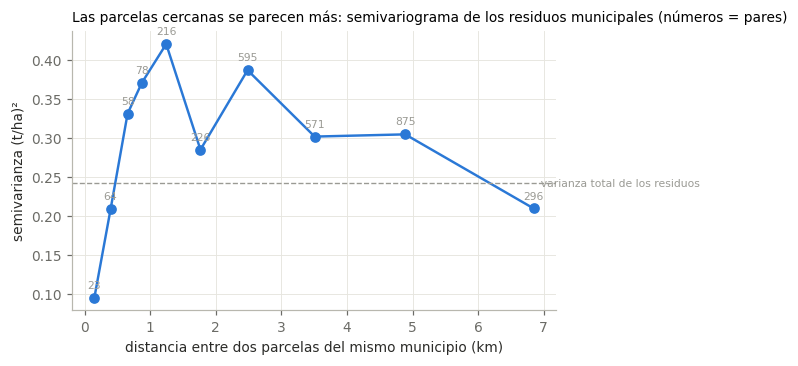

[INFO] Estructura espacial a corta distancia (semivarianza a 0–250 m frente al total) — semivarianza a < 250 m = 39 % de la varianza residual total


In [4]:
# 1.1 · Semivariograma empírico dentro de cada municipio
g = TR.groupby("Municipio").RENDIMIENTO_T_HA
n = g.transform("count")
res_loo = np.where(n > 1, TR.RENDIMIENTO_T_HA - (g.transform("sum") - TR.RENDIMIENTO_T_HA) / (n - 1).clip(lower=1), np.nan)
xy = TR[["x_km", "y_km"]].to_numpy()
D = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1))
mv = TR.Municipio.to_numpy(dtype=object)
iu = np.triu_indices(len(TR), 1)
same = (mv[:, None] == mv[None])[iu]
ok = same & np.isfinite(res_loo[iu[0]]) & np.isfinite(res_loo[iu[1]])
dd, gam = D[iu][ok], 0.5 * (res_loo[iu[0]] - res_loo[iu[1]])[ok] ** 2
edges = np.array([0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8])
cls = np.digitize(dd, edges) - 1
vgd = pd.DataFrame({"cls": cls, "d": dd, "g": gam})
vg = vgd[(vgd.cls >= 0) & (vgd.cls < len(edges) - 1)].groupby("cls").agg(
    distance_km=("d", "mean"), semivariance=("g", "mean"), pairs=("g", "size"))
display(vg.round(3))
sill = np.nanvar(res_loo)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(vg.distance_km, vg.semivariance, marker="o", color="#2a78d6", lw=1.6)
for _, r in vg.iterrows():
    ax.annotate(f"{int(r.pairs)}", (r.distance_km, r.semivariance), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7, color=GREY)
ax.axhline(sill, color=GREY, ls="--", lw=0.9)
ax.text(vg.distance_km.max(), sill, "  varianza total de los residuos", va="center", fontsize=7, color=GREY)
ax.set_xlabel("distancia entre dos parcelas del mismo municipio (km)")
ax.set_ylabel("semivarianza (t/ha)²")
ax.set_title("Las parcelas cercanas se parecen más: semivariograma de los residuos municipales (números = pares)", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "nb06_semivariogram.png", bbox_inches="tight"); plt.show()
short = vg.semivariance.iloc[0] / sill
check("Estructura espacial a corta distancia (semivarianza a 0–250 m frente al total)", short < 0.8,
      f"semivarianza a < 250 m = {100 * short:.0f} % de la varianza residual total", info=True)

## 2 · Código compartido de modelado

Las funciones que usan todos los modelos se escriben en `src/agc_models.py`, para que el cuaderno de predicciones finales y la aplicación web usen **exactamente el mismo código**:
- `select_features`: dentro de un pliegue de entrenamiento, ordena las variables por su |ρ| con el rendimiento dentro de municipio y conserva las *k* primeras, **a lo más una por grupo de redundancia** (casi duplicados, cuaderno 05);
- `prep`: imputación por mediana y estandarización con estadísticas del pliegue de entrenamiento;
- `muni_prior`: media municipal del pliegue de entrenamiento;
- `HierGP`: el proceso gaussiano jerárquico propio.

### El proceso gaussiano jerárquico, en palabras
Un proceso gaussiano predice el rendimiento de una parcela como una combinación ponderada de los rendimientos de entrenamiento, donde los pesos salen de una **función de similitud (núcleo)** entre parcelas. El nuestro suma cuatro tipos de similitud:

$$k(i,j) = \underbrace{\sigma^2_{m}\,\mathbb{1}[\text{mismo municipio}]}_{\text{efecto de municipio}} + \underbrace{\sigma^2_{s}\,\text{Matérn}_{3/2}\!\left(\tfrac{d_{ij}}{\ell_s}\right)}_{\text{vecinas a escala de finca}} + \underbrace{\tfrac{\sigma^2_{f}}{p}\,\mathbf{x}_i^\top\mathbf{x}_j}_{\text{efecto lineal de } p \text{ variables}} + \underbrace{\sigma^2_{n}\,\mathbb{1}[i=j]}_{\text{ruido}}$$

La parte de variables es una regresión lineal bayesiana sobre las *p* variables estandarizadas; tiene una sola varianza σ²_f, así que añadir variables casi no añade libertad de ajuste. (Durante el desarrollo se probó una versión con una escala de longitud por variable y se descartó: con ~110 parcelas de entrenamiento se sobreajustaba, siempre elegía 10 variables y el error de validación cruzada subía 0.04 t/ha.)

Todas las σ² (cuánto explica cada fuente) y ℓ (hasta dónde llega la similitud) se **aprenden de los datos** maximizando la verosimilitud marginal, que equilibra ajuste y complejidad. Para este reto importan tres consecuencias:
1. los municipios pequeños se **contraen** hacia la media general en lugar de confiar en 1–3 parcelas;
2. una parcela toma información de sus vecinas **solo dentro del alcance aprendido** (unos cientos de metros);
3. cada predicción trae su **incertidumbre**, que es la base del «rendimiento financiable» del cuaderno 07.

Para el modelo 6 ajustamos el PG con 0, 3, 6 y 10 variables (seleccionadas en el pliegue de entrenamiento) y conservamos la versión con **mayor evidencia** (verosimilitud marginal). Si las variables satelitales no añaden información a la ubicación, el modelo lo indicará eligiendo 0.

In [5]:
%%writefile {SRC}/agc_models.py
"""agc_models.py: código de modelado compartido del Reto AgroCebada 2026 (lo escribe el cuaderno 06)."""
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve


# ----------------------------------------------------------------------------------------------
# Selección de variables dentro de un pliegue de entrenamiento
# ----------------------------------------------------------------------------------------------
def within_muni_rho(X, y, muni):
    """|rho de Spearman| entre cada columna y y, después de centrar ambas en la media de su municipio."""
    df = X.copy()
    df["_y"] = np.asarray(y, float)
    dm = df.sub(df.groupby(np.asarray(muni)).transform("mean"))
    return dm[X.columns].corrwith(dm["_y"], method="spearman").abs().fillna(0)


def select_features(tr, y, muni, candidates, clusters, k):
    """Las k variables con mayor |rho| dentro de municipio, calculado SOLO en el pliegue de entrenamiento,
    con a lo más una variable por grupo de redundancia (casi duplicados, |rho| >= 0.9)."""
    if k <= 0:
        return []
    X = tr[candidates].astype(float)
    X = X.fillna(X.median())
    rho = within_muni_rho(X, y, muni).sort_values(ascending=False)
    chosen, used = [], set()
    for f in rho.index:
        c = clusters.get(f, f)
        if c in used:
            continue
        chosen.append(f)
        used.add(c)
        if len(chosen) == k:
            break
    return chosen


def prep(tr, te, cols):
    """Imputación por mediana y estandarización con estadísticas del pliegue de ENTRENAMIENTO."""
    if not cols:
        return np.zeros((len(tr), 0)), np.zeros((len(te), 0))
    med = tr[cols].astype(float).median()
    A, B = tr[cols].astype(float).fillna(med), te[cols].astype(float).fillna(med)
    mu, sd = A.mean(), A.std().replace(0, 1).fillna(1)
    return ((A - mu) / sd).to_numpy(), ((B - mu) / sd).to_numpy()


def muni_prior(tr_muni, tr_y, te_muni):
    """Media municipal del pliegue de entrenamiento (media general para municipios no vistos)."""
    s = pd.Series(np.asarray(tr_y, float)).groupby(np.asarray(tr_muni)).mean()
    g = float(np.mean(tr_y))
    return (pd.Series(np.asarray(tr_muni)).map(s).to_numpy(),
            pd.Series(np.asarray(te_muni)).map(s).fillna(g).to_numpy())


# ----------------------------------------------------------------------------------------------
# Proceso gaussiano jerárquico (propio)
# ----------------------------------------------------------------------------------------------
def _matern32(d, l):
    a = np.sqrt(3.0) * d / l
    return (1 + a) * np.exp(-a)


class HierGP:
    """Rendimiento = media general
             + efecto de municipio              (efecto aleatorio: s_muni · 1[mismo municipio])
             + efecto espacial a escala de finca (s_spatial · Matérn-3/2(distancia / l_spatial))
             + efecto de variables satelitales, climáticas o de suelo (opcional; lineal: s_feat · <x_i, x_j> / n_variables)
             + ruido                            (error de reporte o redondeo, variación no explicada)
    Todas las varianzas y escalas de longitud se aprenden maximizando la verosimilitud marginal (evidencia bayesiana)."""

    def __init__(self, use_features=True, restarts=3, seed=0, feat_kernel="linear"):
        # feat_kernel = "linear" (una sola varianza compartida: robusto con ~110 parcelas) o "ard" (una escala por variable;
        # se probó durante el desarrollo y se descartó: la evidencia elegía 10 variables en todos los pliegues y el error de VC subía 0.04 t/ha)
        self.use_features, self.restarts, self.seed, self.fk = use_features, restarts, seed, feat_kernel

    def _K(self, p, A, B, same):
        s_m, s_s, l_s = np.exp(p[0]), np.exp(p[1]), np.exp(p[2])
        D = np.sqrt(((A["xy"][:, None] - B["xy"][None]) ** 2).sum(-1))
        K = s_m * same + s_s * _matern32(D, l_s)
        if self.nf:
            if self.fk == "linear":
                K = K + np.exp(p[3]) * (A["f"] @ B["f"].T) / self.nf
            else:
                Z = (A["f"][:, None, :] - B["f"][None]) / np.exp(p[4:-1])
                K = K + np.exp(p[3]) * np.exp(-0.5 * (Z ** 2).sum(-1))
        return K

    def _nll(self, p):
        K = self._K(p, self.A, self.A, self.same) + (np.exp(p[-1]) + 1e-6) * np.eye(len(self.r))
        try:
            c = cho_factor(K, lower=True)
        except np.linalg.LinAlgError:
            return 1e10
        a = cho_solve(c, self.r)
        return 0.5 * self.r @ a + np.log(np.diag(c[0])).sum() + 0.5 * len(self.r) * np.log(2 * np.pi)

    def fit(self, xy_km, muni, f, y):
        y = np.asarray(y, float)
        self.mu = y.mean()
        self.r = y - self.mu
        self.nf = f.shape[1] if self.use_features else 0
        self.A = {"xy": np.asarray(xy_km, float), "f": np.asarray(f, float)}
        self.muni = np.asarray(muni, dtype=object)
        self.same = (self.muni[:, None] == self.muni[None]).astype(float)
        v = self.r.var()
        nl = self.nf if self.fk == "ard" else 0
        x0 = [np.log(v * .5), np.log(v * .2), np.log(.3)] + ([np.log(v * .1)] + [np.log(1.5)] * nl if self.nf else []) + [np.log(v * .3)]
        lo = [np.log(1e-4), np.log(1e-4), np.log(.03)] + ([np.log(1e-4)] + [np.log(.3)] * nl if self.nf else []) + [np.log(1e-3)]
        hi = [np.log(5), np.log(5), np.log(20)] + ([np.log(5)] + [np.log(50)] * nl if self.nf else []) + [np.log(5)]
        rng = np.random.default_rng(self.seed)
        best = None
        for k in range(self.restarts):
            start = np.clip(np.array(x0) + (rng.normal(0, .5, len(x0)) if k else 0), lo, hi)
            res = minimize(self._nll, start, method="L-BFGS-B", bounds=list(zip(lo, hi)))
            if best is None or res.fun < best.fun:
                best = res
        self.p, self.nll = best.x, float(best.fun)
        K = self._K(self.p, self.A, self.A, self.same) + (np.exp(self.p[-1]) + 1e-6) * np.eye(len(self.r))
        self.c = cho_factor(K, lower=True)
        self.alpha = cho_solve(self.c, self.r)
        return self

    def predict(self, xy_km, muni, f, return_std=False):
        B = {"xy": np.asarray(xy_km, float), "f": np.asarray(f, float)}
        m = np.asarray(muni, dtype=object)
        same = (m[:, None] == self.muni[None]).astype(float)
        Ks = self._K(self.p, B, self.A, same)
        mean = self.mu + Ks @ self.alpha
        if not return_std:
            return mean
        prior = np.exp(self.p[0]) + np.exp(self.p[1]) + (np.exp(self.p[3]) if self.nf else 0)
        v = cho_solve(self.c, Ks.T)
        var_f = np.clip(prior - (Ks * v.T).sum(1), 0, None)
        return mean, np.sqrt(var_f + np.exp(self.p[-1]))      # DE predictiva para una observación nueva

    def params(self):
        e = np.exp(self.p)
        out = {"s_muni": e[0], "s_spatial": e[1], "l_spatial_km": e[2], "noise": e[-1]}
        if self.nf:
            out["s_feat"] = e[3]
            out.update({f"l_feat_{i}": v for i, v in enumerate(e[4:-1])})
        return out

Overwriting /content/drive/MyDrive/AgroCebada/src/agc_models.py


In [6]:
# 2.1 · Importar el código compartido
sys.path.insert(0, str(SRC))
import importlib, agc_models
importlib.reload(agc_models)
from agc_models import select_features, prep, muni_prior, HierGP
print("agc_models cargado desde", agc_models.__file__)

agc_models cargado desde /content/drive/MyDrive/AgroCebada/src/agc_models.py


## 3 · Los modelos y el motor de validación cruzada

Cada modelo es una función `fit_predict(train, test)` que ve **solo** la parte de entrenamiento de un pliegue y devuelve predicciones (y, en los procesos gaussianos, una desviación estándar predictiva) para la parte de prueba. El motor recorre los pliegues fijos y reúne las predicciones fuera de pliegue y las métricas por pliegue.

In [7]:
# 3.1 · Definición de los modelos
Y = "RENDIMIENTO_T_HA"
XY = ["x_km", "y_km"]

def m_baseline(tr, te):
    _, p = muni_prior(tr.Municipio, tr[Y], te.Municipio)
    return p, None

def _ridge_residual(tr, te, k):
    ptr, pte = muni_prior(tr.Municipio, tr[Y], te.Municipio)
    cols = select_features(tr, tr[Y], tr.Municipio, CANDS, CLUSTERS, k)
    A, B = prep(tr, te, cols)
    r = RidgeCV(alphas=np.logspace(-1, 4, 30)).fit(A, tr[Y].to_numpy() - ptr)
    return pte + r.predict(B), ptr + r.predict(A)

def m_ridge(tr, te):
    # una VC interna de 5 pliegues sobre la parte de entrenamiento elige el número de variables
    inner = KFold(5, shuffle=True, random_state=SEED)
    score = {k: [] for k in K_GRID_RIDGE}
    for a, b in inner.split(tr):
        for k in K_GRID_RIDGE:
            p, _ = _ridge_residual(tr.iloc[a], tr.iloc[b], k)
            score[k].append(np.mean((tr[Y].iloc[b].to_numpy() - p) ** 2))
    k = min(score, key=lambda k: np.mean(score[k]))
    m_ridge.chosen.append(k)
    return _ridge_residual(tr, te, k)[0], None
m_ridge.chosen = []

def _tree_residual(tr, te, model):
    ptr, pte = muni_prior(tr.Municipio, tr[Y], te.Municipio)
    cols = select_features(tr, tr[Y], tr.Municipio, CANDS, CLUSTERS, K_TREES)
    A, B = prep(tr, te, cols)
    model.fit(A, tr[Y].to_numpy() - ptr)
    return pte + model.predict(B), None

def m_rf(tr, te):
    return _tree_residual(tr, te, RandomForestRegressor(500, min_samples_leaf=5, max_features=0.33, random_state=SEED, n_jobs=-1))

def m_lgb(tr, te):
    if HAVE_LGB:
        mdl = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=10, subsample=0.8,
                                subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0, random_state=SEED, verbose=-1)
    else:
        mdl = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=300, min_samples_leaf=10,
                                            l2_regularization=5.0, random_state=SEED)
    return _tree_residual(tr, te, mdl)

def _spatial_gp(xy_tr, r_tr):
    kern = ConstantKernel(0.1, (1e-3, 1)) * Matern(length_scale=0.5, length_scale_bounds=(0.05, 20), nu=1.5) + WhiteKernel(0.2, (1e-3, 1))
    return GaussianProcessRegressor(kern, n_restarts_optimizer=2, random_state=SEED).fit(xy_tr, r_tr)

def m_spatial_gp(tr, te):
    ptr, pte = muni_prior(tr.Municipio, tr[Y], te.Municipio)
    gp = _spatial_gp(tr[XY].to_numpy(), tr[Y].to_numpy() - ptr)
    mean, sd = gp.predict(te[XY].to_numpy(), return_std=True)
    return pte + mean, sd

HGP_LOG = []
def m_hgp(tr, te):
    h = HierGP(use_features=False, restarts=HGP_RESTARTS, seed=SEED).fit(tr[XY].to_numpy(), tr.Municipio, np.zeros((len(tr), 0)), tr[Y])
    HGP_LOG.append(h.params())
    return h.predict(te[XY].to_numpy(), te.Municipio, np.zeros((len(te), 0)), return_std=True)

HGPF_LOG = []
def m_hgp_feat(tr, te):
    ranked = select_features(tr, tr[Y], tr.Municipio, CANDS, CLUSTERS, max(HGP_K_GRID))
    best = None
    for k in HGP_K_GRID:
        cols = ranked[:k]
        A, B = prep(tr, te, cols)
        h = HierGP(use_features=k > 0, restarts=HGP_RESTARTS, seed=SEED).fit(tr[XY].to_numpy(), tr.Municipio, A, tr[Y])
        if best is None or h.nll < best[0].nll:
            best = (h, B, cols)
    h, B, cols = best
    HGPF_LOG.append({"k": len(cols), "features": cols, **{k_: v for k_, v in h.params().items() if not k_.startswith("l_feat")}})
    return h.predict(te[XY].to_numpy(), te.Municipio, B, return_std=True)

def m_rk(tr, te):
    # kriging de regresión: ridge sobre variables (k elegido por VC interna) y luego un PG espacial sobre los residuos de ridge
    inner = KFold(5, shuffle=True, random_state=SEED)
    score = {k: [] for k in K_GRID_RIDGE}
    for a, b in inner.split(tr):
        for k in K_GRID_RIDGE:
            p, _ = _ridge_residual(tr.iloc[a], tr.iloc[b], k)
            score[k].append(np.mean((tr[Y].iloc[b].to_numpy() - p) ** 2))
    k = min(score, key=lambda k: np.mean(score[k]))
    p_te, p_tr = _ridge_residual(tr, te, k)
    gp = _spatial_gp(tr[XY].to_numpy(), tr[Y].to_numpy() - p_tr)
    mean, sd = gp.predict(te[XY].to_numpy(), return_std=True)
    return p_te + mean, sd

MODELS_DEF = {
    "0 municipality mean": (m_baseline, "baseline"),
    "1 ridge on residuals": (m_ridge, "features"),
    "2 random forest on residuals": (m_rf, "features"),
    "3 LightGBM on residuals": (m_lgb, "features"),
    "4 spatial GP on residuals": (m_spatial_gp, "spatial"),
    "5 hierarchical GP": (m_hgp, "custom"),
    "6 hierarchical GP + features": (m_hgp_feat, "custom"),
    "7 regression kriging": (m_rk, "spatial"),
}

In [8]:
# 3.2 · Motor de validación cruzada
def metrics(yt, yp):
    e = yt - yp
    return {"rmse": float(np.sqrt(np.mean(e ** 2))), "mae": float(np.mean(np.abs(e)))}

def run(fold_list, scheme):
    oof, scores = [], []
    tr_ids = TR.index.to_numpy()
    for name, (fn, kind) in MODELS_DEF.items():
        t0 = time.time()
        for f in fold_list:
            te_ids = np.array(f["test"])
            trn = TR.loc[np.setdiff1d(tr_ids, te_ids)]
            tst = TR.loc[te_ids]
            pred, sd = fn(trn, tst)
            yt = tst[Y].to_numpy()
            scores.append({"scheme": scheme, "model": name, "kind": kind, "repeat": f.get("repeat", 0), "fold": f["fold"], **metrics(yt, pred)})
            oof.append(pd.DataFrame({"scheme": scheme, "model": name, "repeat": f.get("repeat", 0), "fold": f["fold"],
                                     "ID_POLIGONO": te_ids, "y": yt, "pred": pred, "sd": sd if sd is not None else np.nan}))
        print(f"  {name:32s} {time.time() - t0:6.1f} s")
    return pd.concat(oof, ignore_index=True), pd.DataFrame(scores)

print(f"Esquema principal: {len(FOLDS)} pliegues")
OOF_MAIN, SC_MAIN = run(FOLDS, "main")

Esquema principal: 50 pliegues
  0 municipality mean                 0.2 s
  1 ridge on residuals              326.9 s
  2 random forest on residuals       68.5 s
  3 LightGBM on residuals            16.9 s
  4 spatial GP on residuals          26.9 s
  5 hierarchical GP                  12.5 s
  6 hierarchical GP + features       77.5 s
  7 regression kriging              346.7 s


## 4 · Tabla de posiciones y decisiones

- **RMSE, MAE**: promedio sobre los pliegues. **R²**: calculado con las predicciones fuera de pliegue de cada repetición y luego promediado.
- **Δ frente a la referencia**: media de RMSE(modelo) − RMSE(referencia) en los mismos pliegues (negativo = mejor).
- **EE simple / EE corregido**: ver la introducción. *t* = Δ ÷ EE corregido; |t| > 2 es evidencia fuerte.
- **Decisión**: PASS si Δ < −1 EE simple (la regla fijada antes de modelar).

                                  kind    rmse     mae  r2_pooled  delta_vs_baseline  se_naive  se_corrected  t_corrected      gate
model                                                                                                                              
0 municipality mean           baseline  0.4977  0.3311     0.6401             0.0000    0.0000        0.0000          NaN  baseline
1 ridge on residuals          features  0.5025  0.3486     0.6338             0.0048    0.0027        0.0099       0.4875      fail
2 random forest on residuals  features  0.5130  0.3731     0.6188             0.0153    0.0047        0.0172       0.8895      fail
3 LightGBM on residuals       features  0.5428  0.4009     0.5760             0.0450    0.0080        0.0294       1.5302      fail
4 spatial GP on residuals      spatial  0.4967  0.3427     0.6432            -0.0010    0.0039        0.0143      -0.0695      fail
5 hierarchical GP               custom  0.4938  0.3470     0.6486           

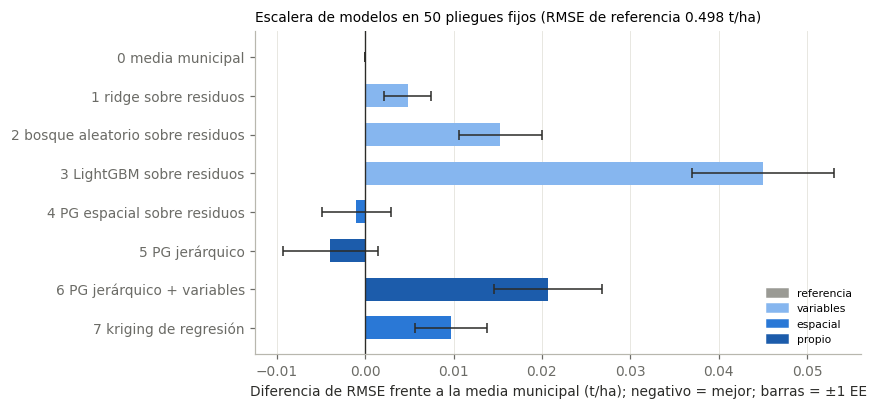

In [9]:
# 4.1 · Tabla de posiciones
def leaderboard(sc, oof, n_test_frac):
    base = sc[sc.model == "0 municipality mean"].set_index(["repeat", "fold"]).rmse
    rows = []
    for name, g in sc.groupby("model", sort=False):
        d = g.set_index(["repeat", "fold"]).rmse - base
        J = len(d)
        naive = d.std(ddof=1) / np.sqrt(J)
        corrected = np.sqrt((1 / J + n_test_frac) * d.var(ddof=1)) if J > 1 else np.nan
        o = oof[oof.model == name]
        r2 = o.groupby("repeat").apply(lambda x: 1 - ((x.y - x.pred) ** 2).sum() / ((x.y - x.y.mean()) ** 2).sum()).mean()
        rows.append({"model": name, "kind": g.kind.iloc[0], "rmse": g.rmse.mean(), "mae": g.mae.mean(), "r2_pooled": r2,
                     "delta_vs_baseline": d.mean(), "se_naive": naive, "se_corrected": corrected,
                     "t_corrected": d.mean() / corrected if corrected and corrected > 0 else np.nan,
                     "gate": "PASS" if d.mean() < -naive else ("baseline" if name.startswith("0") else "fail")})
    return pd.DataFrame(rows).set_index("model")

n_te = np.mean([len(f["test"]) for f in FOLDS])
LB = leaderboard(SC_MAIN, OOF_MAIN, n_te / (len(TR) - n_te))
display(LB.round(4))
LB.to_csv(MODELS / "leaderboard_nb06.csv")

b0 = LB.loc["0 municipality mean", "rmse"]
if OFFICIAL:
    off = OFFICIAL["main"]["municipality mean"]["rmse"]
    check("El motor reproduce la referencia oficial del cuaderno 05", abs(b0 - off) < 0.005 or N_REPEATS < 10,
          f"motor {b0:.4f} frente a oficial {off:.4f} t/ha" + ("" if N_REPEATS == 10 else f" (corrida rápida con {N_REPEATS} repeticiones)"))
best = LB.drop(index="0 municipality mean").rmse.idxmin()
check("Mejor modelo en el esquema principal", True,
      f"{best}: RMSE {LB.loc[best, 'rmse']:.4f} (Δ {LB.loc[best, 'delta_vs_baseline']:+.4f}, EE simple {LB.loc[best, 'se_naive']:.4f}, "
      f"t corregido = {LB.loc[best, 't_corrected']:.2f}); R² agrupado {LB.loc[best, 'r2_pooled']:.3f}", info=True)
passed = LB.index[LB.gate == "PASS"].tolist()
check("Modelos que pasan la regla de decisión (Δ < −1 EE simple)", len(passed) > 0, ", ".join(passed) if passed else "ninguno: solo se usaría la referencia")

fig, ax = plt.subplots(figsize=(8, 3.8))
lb = LB.iloc[::-1]
ax.barh([NOMBRES.get(m, m) for m in lb.index], lb.delta_vs_baseline, xerr=lb.se_naive, color=[COLORS[k] for k in lb.kind], height=0.6,
        error_kw={"ecolor": INK, "lw": 1, "capsize": 3})
ax.axvline(0, color=INK, lw=0.9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Diferencia de RMSE frente a la media municipal (t/ha); negativo = mejor; barras = ±1 EE")
ax.set_title(f"Escalera de modelos en {len(FOLDS)} pliegues fijos (RMSE de referencia {b0:.3f} t/ha)", loc="left", fontsize=9)
ax.legend(handles=[matplotlib.patches.Patch(color=c, label=TIPOS[k]) for k, c in COLORS.items()], fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "nb06_leaderboard.png", bbox_inches="tight"); plt.show()

In [10]:
# 4.2 · ¿Qué aprendieron los modelos propios?
hp = pd.DataFrame(HGP_LOG)
tot = hp[["s_muni", "s_spatial", "noise"]].sum(axis=1)
share = pd.DataFrame({"municipality": hp.s_muni / tot, "farm-scale spatial": hp.s_spatial / tot, "noise": hp.noise / tot})
print("PG jerárquico (solo ubicación), mediana sobre los pliegues:")
display(pd.concat([hp[["s_muni", "s_spatial", "l_spatial_km", "noise"]].median().rename("value"),
                   share.median().rename("share of variance")], axis=1).round(3))
within = hp.s_spatial / (hp.s_spatial + hp.noise)
check("PG jerárquico: alcance a escala de finca y proporción de la variación dentro de municipio", True,
      f"alcance ℓ ≈ {hp.l_spatial_km.median():.2f} km; proporción espacialmente estructurada de la varianza dentro de municipio ≈ {100 * within.median():.0f} %", info=True)
kf = pd.DataFrame(HGPF_LOG)
kdist = kf.k.value_counts().sort_index()
display(kdist.rename("folds").to_frame().T)
top_feats = pd.Series([f for fs in kf.features for f in fs]).value_counts().head(10)
check("PG jerárquico + variables: ¿cuántas variables elige la evidencia?", True,
      "; ".join(f"k={k}: {v} pliegues" for k, v in kdist.items()) + (f". Más elegidas: {', '.join(top_feats.index[:5])}" if len(top_feats) else ""), info=True)
if m_ridge.chosen:
    check("Ridge: número de variables elegido por VC interna", True, pd.Series(m_ridge.chosen).value_counts().sort_index().to_dict(), info=True)

PG jerárquico (solo ubicación), mediana sobre los pliegues:
                    value  share of variance
s_muni              0.532                NaN
s_spatial           0.193                NaN
l_spatial_km        0.295                NaN
noise               0.063              0.080
municipality          NaN              0.674
farm-scale spatial    NaN              0.248
[INFO] PG jerárquico: alcance a escala de finca y proporción de la variación dentro de municipio — alcance ℓ ≈ 0.30 km; proporción espacialmente estructurada de la varianza dentro de municipio ≈ 76 %
k      3   6   10
folds  21  17  12
[INFO] PG jerárquico + variables: ¿cuántas variables elige la evidencia? — k=3: 21 pliegues; k=6: 17 pliegues; k=10: 12 pliegues. Más elegidas: s2_ndvi_integral_grainfill, s2_ndvi_pos, s2_ndvi_base_left, pl_ndvi_base_left, clim_pet_cycle
[INFO] Ridge: número de variables elegido por VC interna — {5: 12, 10: 12, 20: 8, 40: 18}


## 5 · ¿Son honestas las incertidumbres?

Los procesos gaussianos dan a cada predicción una desviación estándar. Si es honesta, cerca del **80 %** de los rendimientos reales debería caer dentro de predicción ± 1.28 DE y el **90 %** dentro de ± 1.64 DE. El cuaderno 07 calibra estos intervalos con predicción conforme; aquí solo revisamos la cobertura sin calibrar.

                              coverage_80  coverage_90  median_sd
model                                                            
4 spatial GP on residuals           0.825        0.890      0.461
5 hierarchical GP                   0.841        0.900      0.488
6 hierarchical GP + features        0.806        0.881      0.479
7 regression kriging                0.791        0.888      0.445
[PASS] Cobertura de intervalos sin calibrar de 5 hierarchical GP — 80 % nominal → 84 %; 90 % nominal → 90 %


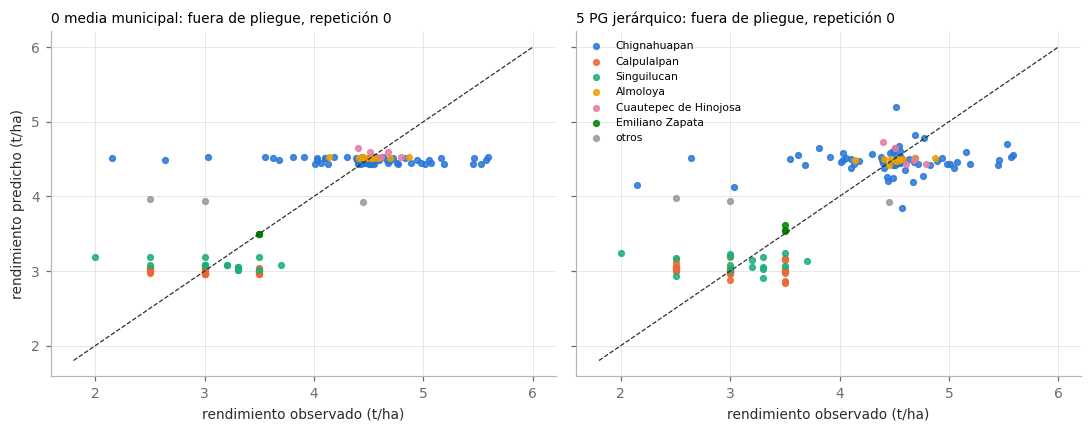

In [11]:
# 5.1 · Cobertura de intervalos y observado frente a predicho
cov_rows = []
for name in [m for m in LB.index if OOF_MAIN[OOF_MAIN.model == m].sd.notna().all()]:
    o = OOF_MAIN[OOF_MAIN.model == name]
    z = np.abs(o.y - o.pred) / o.sd
    cov_rows.append({"model": name, "coverage_80": (z <= Z80).mean(), "coverage_90": (z <= Z90).mean(), "median_sd": o.sd.median()})
COV = pd.DataFrame(cov_rows).set_index("model")
display(COV.round(3))
gp_best = COV.index[0] if len(COV) else None
if gp_best is not None:
    bm = LB.loc[COV.index].rmse.idxmin()
    check(f"Cobertura de intervalos sin calibrar de {bm}", abs(COV.loc[bm, "coverage_80"] - 0.8) <= 0.07,
          f"80 % nominal → {100 * COV.loc[bm, 'coverage_80']:.0f} %; 90 % nominal → {100 * COV.loc[bm, 'coverage_90']:.0f} %")

o = OOF_MAIN[(OOF_MAIN.model == best) & (OOF_MAIN.repeat == 0)].merge(TR[["Municipio"]], left_on="ID_POLIGONO", right_index=True)
ob = OOF_MAIN[(OOF_MAIN.model == "0 municipality mean") & (OOF_MAIN.repeat == 0)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
top = TR.Municipio.value_counts().index[:6].tolist()
mc = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
for ax, df, title in [(axes[0], ob.merge(TR[["Municipio"]], left_on="ID_POLIGONO", right_index=True), "0 municipality mean"), (axes[1], o, best)]:
    for k, m in enumerate(top):
        s = df[df.Municipio == m]
        ax.scatter(s.y, s.pred, s=14, color=mc[k], label=m, alpha=0.85)
    s = df[~df.Municipio.isin(top)]
    ax.scatter(s.y, s.pred, s=14, color=GREY, label="otros", alpha=0.85)
    lim = [1.8, 6]
    ax.plot(lim, lim, color=INK, lw=0.8, ls="--")
    ax.set_title(f"{NOMBRES.get(title, title)}: fuera de pliegue, repetición 0", loc="left", fontsize=9)
    ax.set_xlabel("rendimiento observado (t/ha)")
axes[0].set_ylabel("rendimiento predicho (t/ha)")
axes[1].legend(fontsize=7, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "nb06_observed_vs_predicted.png", bbox_inches="tight"); plt.show()

## 6 · La prueba más difícil: bloques espaciales

Los mismos modelos, pero ahora se apartan zonas geográficas completas. Aquí los modelos espaciales no pueden tomar información de vecinas cercanas (no hay ninguna en entrenamiento), así que su ventaja debería reducirse. Esto mide cómo se transferiría el enfoque a zonas nuevas, y lo reportamos por transparencia.

In [12]:
# 6.1 · Bloques espaciales
OOF_SP, SC_SP = run(SPATIAL, "spatial")
LB_SP = leaderboard(SC_SP, OOF_SP, np.mean([len(f["test"]) for f in SPATIAL]) / (len(TR) - np.mean([len(f["test"]) for f in SPATIAL])))
display(LB_SP[["rmse", "mae", "r2_pooled", "delta_vs_baseline", "se_naive"]].round(4))
pd.concat([OOF_MAIN, OOF_SP]).to_parquet(MODELS / "oof_nb06.parquet", index=False)
LB_SP.to_csv(MODELS / "leaderboard_nb06_spatial.csv")
b = LB_SP.drop(index="0 municipality mean").rmse.idxmin()
check("Mejor modelo en bloques espaciales", True, f"{b}: RMSE {LB_SP.loc[b, 'rmse']:.4f} (Δ {LB_SP.loc[b, 'delta_vs_baseline']:+.4f})", info=True)

  0 municipality mean                 0.0 s
  1 ridge on residuals               33.1 s
  2 random forest on residuals        6.1 s
  3 LightGBM on residuals             1.5 s
  4 spatial GP on residuals           1.5 s
  5 hierarchical GP                   1.2 s
  6 hierarchical GP + features        7.8 s
  7 regression kriging               33.9 s
                                rmse     mae  r2_pooled  delta_vs_baseline  se_naive
model                                                                               
0 municipality mean           0.6354  0.4570     0.3998             0.0000    0.0000
1 ridge on residuals          0.6277  0.4582     0.4070            -0.0076    0.0080
2 random forest on residuals  0.6191  0.4528     0.4240            -0.0162    0.0134
3 LightGBM on residuals       0.6260  0.4632     0.4139            -0.0094    0.0185
4 spatial GP on residuals     0.6356  0.4573     0.3994             0.0003    0.0001
5 hierarchical GP             0.6390  0.4685     0.39

In [13]:
# 6.2 · Reporte
def md_table(df):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.4g}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

chk = pd.DataFrame(CHECKS)
lines = ["# Reporte del cuaderno 06: escalera de modelos",
         f"Generado {datetime.now():%Y-%m-%d %H:%M} · Colab: {IN_COLAB} · pliegues: {len(FOLDS)} principales, {len(SPATIAL)} espaciales · LightGBM: {HAVE_LGB}", "",
         f"**Conteo de estados:** {chk.status.value_counts().to_dict()}", "",
         "## Verificaciones", md_table(chk), "",
         "## Tabla de posiciones: esquema principal", md_table(LB.round(4).reset_index()), "",
         "## Tabla de posiciones: bloques espaciales", md_table(LB_SP[["rmse", "mae", "r2_pooled", "delta_vs_baseline", "se_naive"]].round(4).reset_index()), "",
         "## Semivariograma de los residuos municipales", md_table(vg.round(3).reset_index(drop=True)), "",
         "## Parámetros del PG jerárquico (mediana sobre pliegues)", md_table(hp.median().round(4).rename("value").reset_index()), "",
         "## Variables elegidas por evidencia (modelo 6)", md_table(kdist.rename("folds").reset_index()), "",
         "## Cobertura de intervalos (desviaciones estándar del PG sin calibrar)", md_table(COV.round(3).reset_index())]
(QA / "nb06_report.md").write_text("\n".join(lines), encoding="utf-8")
print(chk.status.value_counts().to_dict())
problems = chk[chk.status.isin(["WARN", "FAIL"])]
display(problems if len(problems) else "Todas las verificaciones pasaron.")
print(f"Reporte: {QA / 'nb06_report.md'}")

{'INFO': 6, 'PASS': 2, 'WARN': 1}
                                               check status                                 detail
3  Modelos que pasan la regla de decisión (Δ < −1...   WARN  ninguno: solo se usaría la referencia
Reporte: /content/drive/MyDrive/AgroCebada/qa/nb06_report.md
